# 06 Variables datées

Deux familles de plus, les concerts et festivals de l'artiste (`l_artist_event`) et ses liens URL (`l_artist_url`). Elles se datent à T0 comme les liens de membres du notebook 03. Les lignes de ces tables ont un id croissant et une date de mise à jour. Leur date de création s'estime donc avec `date_creation`. Seuls les liens créés avant T0 comptent.

Comme au notebook 03, l'étude n'utilise que les cohortes d'entraînement (T0 = 2014 à 2018). La cohorte de test (T0 = 2021) n'est calculée que pour la table finale.

In [1]:
import sys

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from sklearn.base import clone
from sklearn.ensemble import VotingClassifier
from sklearn.metrics import average_precision_score

sys.path.append("..")
from src.modelisation import (
    BOOSTING, COLONNES_PAR_FAMILLE, FORET, LOGISTIQUE, WEB, auc, boosting, foret, intervalle_ecart, logistique, preparer,
)
from src.transformation import GROUPES_URL, cohorte, date_creation, liens_url, lire, sorties_du_projet, web

ENTRAINEMENT, TEST = [2014, 2015, 2016, 2017, 2018], 2021

sorties = sorties_du_projet()

## 1. Concerts et festivals

Jouer en concert et en festival, c'est déjà avoir un public.

Les événements n'existent dans MusicBrainz que depuis le 17 novembre 2014. On mesure d'abord, par cohorte, la part d'artistes qui ont au moins un événement daté d'avant T0 et lié à eux avant T0.

In [2]:
evenements = lire("event", ["id", "begin_date_year"]).rename(columns={"id": "event"})
liens_evenements = date_creation(lire("l_artist_event", ["id", "entity0", "entity1", "last_updated"]))
liens_evenements = liens_evenements.rename(columns={"entity0": "artist", "entity1": "event"}).merge(evenements, on="event")
print(f"plus ancien lien artiste-événement : {liens_evenements['creation'].min():%d/%m/%Y}")

couverture = {}
for t0 in ENTRAINEMENT:
    population = cohorte(sorties, t0)
    connus = liens_evenements[(liens_evenements["creation"].dt.year < t0) & (liens_evenements["begin_date_year"] < t0)]
    avec = pd.Series(population.index.isin(connus["artist"]), index=population.index)
    couverture[t0] = {
        "% des artistes": 100 * avec.mean(),
        "% des positifs": 100 * avec[population].mean(),
        "% des négatifs": 100 * avec[~population].mean(),
    }
pd.DataFrame(couverture).T.round(2)

plus ancien lien artiste-événement : 17/11/2014


,% des artistes,% des positifs,% des négatifs
2014,0.00,0.00,0.00
2015,1.27,3.46,1.24
2016,5.17,15.66,5.06
2017,6.82,18.91,6.70
2018,7.89,17.26,7.79


Le plus ancien lien artiste-événement date du 17/11/2014. Aucun artiste de la cohorte 2014 n'a d'événement connu à T0. On passe à 1,27 % en 2015, puis 5,17 % à 7,89 % de 2016 à 2018. Le signal existe, 15,66 % des positifs de 2016 ont un événement connu contre 5,06 % des négatifs. Mais les deux découpages du notebook 05 s'entraînent sur 2014 et 2015, où il n'y a presque rien à apprendre. On écarte cette famille.

## 2. Liens URL

Un artiste présent en ligne et déjà référencé ailleurs est sans doute suivi de près.

Les types de liens forment cinq groupes (`GROUPES_URL`), d'après la liste de MusicBrainz.

- Le site officiel.
- Les réseaux sociaux, avec SoundCloud et YouTube.
- Le streaming et le téléchargement.
- Bandcamp, à part.
- Les bases de données (Discogs, Wikidata, Wikipedia, AllMusic...).

Les autres types (biographie, paroles, blog...) ne comptent que dans le nombre total de liens. Le tableau donne les domaines les plus fréquents des trois groupes qui réunissent plusieurs sites, sur les liens créés avant 2018.

In [3]:
adresses = lire("url", ["id", "url"]).rename(columns={"id": "url", "url": "adresse"})
liens = liens_url()
liens = liens[liens["creation"].dt.year < 2018].merge(adresses, on="url")
liens["domaine"] = liens["adresse"].str.extract(r"://(?:www\.)?([^/]+)", expand=False)
domaines = {}
for groupe in ["reseaux_sociaux", "streaming", "bases"]:
    part = 100 * liens.loc[liens["type_lien"].isin(GROUPES_URL[groupe]), "domaine"].value_counts(normalize=True).head(5)
    domaines[groupe] = [f"{domaine} ({p:.1f} %)" for domaine, p in part.items()]
pd.DataFrame(domaines)

,reseaux_sociaux,streaming,bases
0,facebook.com (29.5 %),open.spotify.com (26.2 %),discogs.com (48.6 %)
1,myspace.com (18.7 %),itunes.apple.com (26.1 %),wikidata.org (16.3 %)
2,twitter.com (16.9 %),beatport.com (7.2 %),allmusic.com (7.4 %)
3,soundcloud.com (13.2 %),play.google.com (5.5 %),rateyourmusic.com (5.3 %)
4,youtube.com (11.1 %),deezer.com (3.8 %),viaf.org (4.8 %)


Les réseaux sociaux sont surtout Facebook (29,5 %), Myspace (18,7 %) et Twitter (16,9 %). Le streaming, c'est surtout Spotify (26,2 %) et iTunes (26,1 %). Les bases, ce sont Discogs (48,6 %) et Wikidata (16,3 %).

Comme pour les liens de membres, on compare la part des liens créés après T0 chez les positifs et chez les négatifs.

In [4]:
tardifs = []
for t0 in ENTRAINEMENT:
    population = cohorte(sorties, t0)
    liens = liens_url()
    liens = liens[liens["artist"].isin(population.index)].copy()
    liens["y"] = liens["artist"].map(population)
    liens["créé après T0"] = liens["creation"].dt.year >= t0
    tardifs.append(liens)
pd.concat(tardifs).groupby("y")["créé après T0"].mean().round(3)

y
False    0.603
True     0.750
Name: créé après T0, dtype: float64

75,0 % des liens URL des positifs ont été créés après T0, contre 60,3 % pour les négatifs. On ne garde donc que les liens créés avant T0.

In [5]:
tables = {t0: cohorte(sorties, t0).rename("y").to_frame().join(web(sorties, t0)) for t0 in ENTRAINEMENT}
en_ligne = pd.concat(tables, names=["t0", "artist"])
variables_web = en_ligne.columns.drop("y")
print(f"{len(en_ligne)} lignes, {en_ligne['y'].mean():.2%} de positifs")
pd.DataFrame({
    "artistes concernés": (en_ligne[variables_web] > 0).sum(),
    "% de positifs si > 0": [100 * en_ligne.loc[en_ligne[c] > 0, "y"].mean() for c in variables_web],
    "% de positifs sinon": [100 * en_ligne.loc[en_ligne[c] == 0, "y"].mean() for c in variables_web],
    "AUC": [auc(en_ligne[c], en_ligne["y"]) for c in variables_web],
}).round({"% de positifs si > 0": 2, "% de positifs sinon": 2, "AUC": 3})

257807 lignes, 1.06% de positifs


,artistes concernés,% de positifs si > 0,% de positifs sinon,AUC
liens_url,182209,1.21,0.70,0.622
site_officiel,82627,1.51,0.85,0.569
reseaux_sociaux,126344,1.39,0.74,0.578
streaming,19034,2.00,0.98,0.533
bandcamp,43307,0.49,1.17,0.454
bases,110366,1.46,0.76,0.581


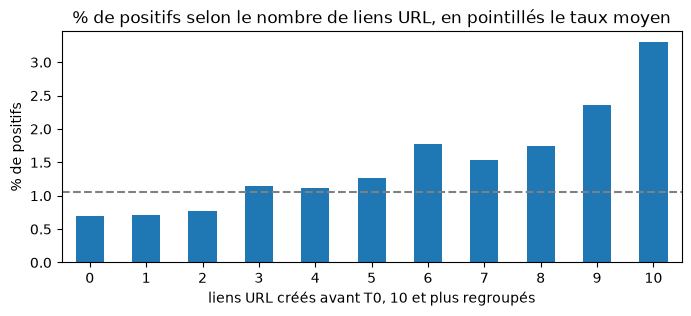

,% avec au moins un lien,AUC de liens_url
2014,61.6,0.604
2015,62.2,0.626
2016,68.8,0.636
2017,76.2,0.638
2018,79.7,0.622


In [6]:
taux = 100 * en_ligne["y"].groupby(en_ligne["liens_url"].astype(int).clip(upper=10)).mean()
ax = taux.plot.bar(figsize=(8, 3), color="tab:blue", rot=0, xlabel="liens URL créés avant T0, 10 et plus regroupés",
                   ylabel="% de positifs", title="% de positifs selon le nombre de liens URL, en pointillés le taux moyen")
ax.axhline(100 * en_ligne["y"].mean(), color="grey", linestyle="--")
plt.show()

pd.DataFrame({t0: {"% avec au moins un lien": 100 * (g["liens_url"] > 0).mean(), "AUC de liens_url": auc(g["liens_url"], g["y"])}
              for t0, g in en_ligne.groupby(level="t0")}).T.round({"% avec au moins un lien": 1, "AUC de liens_url": 3})

Au moins un lien connu à T0 donne 1,21 % de positifs, contre 0,70 % sans lien. Le taux monte avec le nombre de liens (AUC 0,622, plus que `label_tremplin` au notebook 03). Les bases de données, les réseaux sociaux et le site officiel vont dans le même sens (AUC 0,581, 0,578 et 0,569). Le streaming est plus rare (19 034 artistes) mais double le taux, 2,00 % contre 0,98 %. Bandcamp va dans l'autre sens, 0,49 % de positifs avec une page contre 1,17 % sans (AUC 0,454).

La part d'artistes avec au moins un lien passe de 61,6 % en 2014 à 79,7 % en 2018. L'AUC de `liens_url` reste pourtant entre 0,604 et 0,638.

## 3. Test anti-fuite

On ajoute de fausses données à la cohorte T0 = 2016. Ce sont les fausses sorties en major du notebook 03. S'y ajoutent des liens URL de tous les groupes, créés le 1er janvier 2016. La famille ne doit pas changer, et elle doit changer si ces liens datent de la veille.

In [7]:
t0 = 2016
population = cohorte(sorties, t0).index
reelles = sorties[sorties["artist"].isin(population)]
futures = reelles.sample(5000, random_state=0).assign(annee=t0 + 1, major=True)
tardives = reelles[reelles["annee"] < t0].sample(5000, random_state=1).assign(date_ajout=pd.Timestamp(f"{t0}-06-01"), major=True)
types = [t for groupe in GROUPES_URL.values() for t in groupe]
faux_liens = pd.DataFrame({
    "artist": pd.Series(population).sample(100 * len(types), replace=True, random_state=2, ignore_index=True),
    "type_lien": types * 100,
    "creation": pd.Timestamp(f"{t0}-01-01"),
})
faussees = pd.concat([sorties, futures, tardives])

pd.testing.assert_frame_equal(web(sorties, t0), web(faussees, t0, liens=pd.concat([liens_url(), faux_liens])))
print(f"web inchangée avec {len(futures) + len(tardives)} fausses sorties et {len(faux_liens)} faux liens créés en {t0}")
veille = faux_liens.assign(creation=pd.Timestamp(f"{t0 - 1}-12-31"))
print("web change avec les mêmes liens créés la veille :", not web(sorties, t0, liens=pd.concat([liens_url(), veille])).equals(web(sorties, t0)))

web inchangée avec 10000 fausses sorties et 3200 faux liens créés en 2016


web change avec les mêmes liens créés la veille : True


## 4. Table finale

`data/features_web.parquet` reprend `data/features.parquet` et y ajoute les variables web, pour les cohortes d'entraînement et de test.

In [8]:
table = pd.read_parquet("../data/features.parquet")
nouvelles = pd.concat({t0: web(sorties, t0) for t0 in ENTRAINEMENT + [TEST]}, names=["t0", "artist"]).reset_index()
table = table.merge(nouvelles, on=["t0", "artist"], how="left")
print(f"valeurs manquantes dans les variables web : {table[WEB['web']].isna().sum().sum()}")
table.to_parquet("../data/features_web.parquet", index=False)
print(f"{table.shape[1] - 3} variables")
table.groupby("t0").size().rename("artistes")

valeurs manquantes dans les variables web : 0


36 variables


t0
2014    41081
2015    47075
2016    51359
2017    56812
2018    61480
2021    82372
Name: artistes, dtype: int64

## 5. Apport en validation

Les modèles et réglages du notebook 05, moyenne logistique + forêt comprise (partie 13), sont entraînés avec et sans la famille web. On garde ses deux découpages. L'intervalle à 95 % est celui de l'écart d'AUC PR (`intervalle_ecart`, 200 tirages avec remise).

In [9]:
table = pd.read_parquet("../data/features_web.parquet")
X_sans, y = preparer(table)
X_avec, _ = preparer(table, COLONNES_PAR_FAMILLE | WEB)
t0 = table["t0"].to_numpy()
candidats = {
    "régression logistique": logistique(**LOGISTIQUE),
    "forêt aléatoire": foret(**FORET),
    "gradient boosting": boosting(**BOOSTING),
    "moyenne logistique + forêt": VotingClassifier([("logistique", logistique(**LOGISTIQUE)), ("forêt", foret(**FORET))], voting="soft"),
}

lignes = {}
for decoupage, annees, evaluation in [("2014 vers 2017", [2014], 2017), ("2014 et 2015 vers 2018", [2014, 2015], 2018)]:
    entrainement, evalue = np.isin(t0, annees), t0 == evaluation
    avec_web = {}
    for nom, modele in candidats.items():
        sans = clone(modele).fit(X_sans[entrainement], y[entrainement]).predict_proba(X_sans[evalue])[:, 1]
        avec = clone(modele).fit(X_avec[entrainement], y[entrainement]).predict_proba(X_avec[evalue])[:, 1]
        avec_web[nom] = avec
        bas, haut = intervalle_ecart(y[evalue], avec, sans)
        ap_sans, ap_avec = average_precision_score(y[evalue], sans), average_precision_score(y[evalue], avec)
        lignes[(decoupage, nom)] = {"sans web": ap_sans, "avec web": ap_avec, "écart": ap_avec - ap_sans, "intervalle bas": bas, "intervalle haut": haut}
    for nom in ["régression logistique", "forêt aléatoire", "gradient boosting"]:
        bas, haut = intervalle_ecart(y[evalue], avec_web["moyenne logistique + forêt"], avec_web[nom])
        print(f"{decoupage}, avec web, AUC PR moyenne - {nom} : intervalle à 95 % [{bas:.4f}, {haut:.4f}]")
pd.DataFrame(lignes).T.round(4)

2014 vers 2017, avec web, AUC PR moyenne - régression logistique : intervalle à 95 % [0.0012, 0.0042]


2014 vers 2017, avec web, AUC PR moyenne - forêt aléatoire : intervalle à 95 % [-0.0041, 0.0119]


2014 vers 2017, avec web, AUC PR moyenne - gradient boosting : intervalle à 95 % [-0.0072, 0.0091]


2014 et 2015 vers 2018, avec web, AUC PR moyenne - régression logistique : intervalle à 95 % [0.0016, 0.0064]


2014 et 2015 vers 2018, avec web, AUC PR moyenne - forêt aléatoire : intervalle à 95 % [0.0052, 0.0239]


2014 et 2015 vers 2018, avec web, AUC PR moyenne - gradient boosting : intervalle à 95 % [0.0008, 0.0201]


sans web  avec web   écart  \
2014 vers 2017         régression logistique         0.0374    0.0389  0.0015   
                       forêt aléatoire               0.0340    0.0379  0.0039   
                       gradient boosting             0.0376    0.0412  0.0035   
                       moyenne logistique + forêt    0.0396    0.0415  0.0019   
2014 et 2015 vers 2018 régression logistique         0.0479    0.0502  0.0023   
                       forêt aléatoire               0.0364    0.0401  0.0037   
                       gradient boosting             0.0409    0.0445  0.0036   
                       moyenne logistique + forêt    0.0502    0.0542  0.0040   

                                                   intervalle bas  \
2014 vers 2017         régression logistique              -0.0018   
                       forêt aléatoire                     0.0009   
                       gradient boosting                   0.0000   
                       moyenne logistique + forêt         -0.0012   
2014 et 2015 vers 2018 régression logistique              -0.0014   
                       forêt aléatoire                    -0.0002   
                       gradient boosting                  -0.0016   
                       moyenne logistique + forêt         -0.0001   

                                                   intervalle haut  
2014 vers 2017         régression logistique                0.0043  
                       forêt aléatoire                      0.0082  
                       gradient boosting                    0.0079  
                       moyenne logistique + forêt           0.0043  
2014 et 2015 vers 2018 régression logistique                0.0057  
                       forêt aléatoire                      0.0067  
                       gradient boosting                    0.0072  
                       moyenne logistique + forêt           0.0071

Sans web, on retrouve les AUC PR du notebook 05. Avec, les quatre modèles gagnent un peu sur les deux découpages, de 0,0015 à 0,0040. Mais le gain n'est net que pour la forêt en 2017 ([0,0009 ; 0,0082]).

Avec la famille web, la moyenne reste première sur les deux découpages (0,0415 en 2017, 0,0542 en 2018). Elle devance nettement la régression logistique sur les deux, la forêt et le boosting en 2018 seulement. La moyenne logistique + forêt reste donc le meilleur choix, mais l'apport du web n'y est plus net.

## Sources

- Les id et dates de mise à jour des tables, https://github.com/metabrainz/musicbrainz-server/blob/1bedfed82b794a23ced029d397da01f2bd4d4256/admin/sql/CreateTables.sql
- Les événements, ajoutés à MusicBrainz le 17 novembre 2014, https://blog.metabrainz.org/2014/11/18/schema-change-update-2014-11-17/